# Macro-F1, MCC e Balanced Accuracy (sentimento -1 / 0 / +1)

Notebook adaptado para calcular **três métricas globais** a partir da matriz de confusão (linhas = real, colunas = predito):

| Métrica | Definição |
|---|---|
| **Macro-F1** | $\text{Macro-F1} = \frac{1}{K}\sum_{i=1}^{K} F1_i$ — média simples do F1 de cada classe, sem ponderar pelo tamanho |
| **MCC** (Gorodkin, multiclasse) | $\text{MCC}=\dfrac{c\,s-\sum_k p_k t_k}{\sqrt{(s^2-\sum_k p_k^2)(s^2-\sum_k t_k^2)}}$, com $c$ = acertos (traço), $s$ = total, $t_k$ = reais da classe $k$, $p_k$ = preditos da classe $k$ |
| **Balanced Accuracy** | $\frac{1}{K}\sum_{i=1}^{K} \text{Recall}_i$ — equivale ao Macro-Recall |

Funciona no **Colab** (upload do CSV) e **localmente** (basta definir `CAMINHO_CSV`).

In [ ]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

ROTULOS = [-1, 0, 1]
NOMES = {-1: "Negativo (-1)", 0: "Neutro (0)", 1: "Positivo (+1)"}
EM_COLAB = "google.colab" in sys.modules
MAPA_TEXTO = {"neg": -1, "negativo": -1, "negative": -1,
              "neu": 0, "neutro": 0, "neutral": 0,
              "pos": 1, "positivo": 1, "positive": 1}

## 1. Funções

In [ ]:
def dividir(a, b):
    """Divisão segura: 0.0 quando o denominador é zero."""
    return float(a) / float(b) if b else 0.0


def ler_csv(caminho):
    """Lê o CSV detectando o separador; tenta utf-8-sig e depois latin-1."""
    erros = []
    for enc in ("utf-8-sig", "latin-1"):
        try:
            return pd.read_csv(caminho, sep=None, engine="python", encoding=enc)  # usa o parâmetro!
        except (UnicodeDecodeError, pd.errors.ParserError) as e:
            erros.append(f"{enc}: {e}")
        except FileNotFoundError:
            raise SystemExit(f"Arquivo não encontrado: {caminho}")
        except pd.errors.EmptyDataError:
            raise SystemExit(f"Arquivo CSV vazio: {caminho}")
    raise SystemExit("Não foi possível ler o CSV.\n  - " + "\n  - ".join(erros))


def normalizar_rotulos(serie):
    s = serie.astype(str).str.strip().str.lower().str.replace(",", ".", regex=False)
    return pd.to_numeric(s.replace(MAPA_TEXTO), errors="coerce")


def preparar_dados(df, col_pred, col_gold, rotulos, cols_prob=None):
    col_pred = col_pred or df.columns[0]
    col_gold = col_gold or df.columns[1]
    for c in (col_pred, col_gold, *(cols_prob or [])):
        if c not in df.columns:
            raise SystemExit(f"Coluna '{c}' não encontrada. Disponíveis: {list(df.columns)}")
    pred, gold = normalizar_rotulos(df[col_pred]), normalizar_rotulos(df[col_gold])
    validos = pred.notna() & gold.notna()
    probas = None
    if cols_prob:
        if len(cols_prob) != len(rotulos):
            raise SystemExit(f"PROB_COLS precisa de {len(rotulos)} colunas (uma por classe, na ordem {rotulos}).")
        probas = df[cols_prob].apply(pd.to_numeric, errors="coerce")
        validos &= probas.notna().all(axis=1)
    fora = validos & (~pred.isin(rotulos) | ~gold.isin(rotulos))
    if (~validos).sum():
        print(f"[aviso] {int((~validos).sum())} linha(s) ignorada(s): valor ausente/não numérico.")
    if fora.sum():
        print(f"[aviso] {int(fora.sum())} linha(s) ignorada(s): rótulo fora de {rotulos}.")
    validos &= ~fora
    if validos.sum() == 0:
        raise SystemExit("Nenhuma linha válida para avaliar.")
    p = probas[validos].to_numpy(dtype=float) if probas is not None else None
    return pred[validos].astype(int).to_numpy(), gold[validos].astype(int).to_numpy(), p


def matriz_confusao(y_gold, y_pred, rotulos):
    """Linhas = real; colunas = predito."""
    idx = {r: i for i, r in enumerate(rotulos)}
    cm = np.zeros((len(rotulos),) * 2, dtype=int)
    np.add.at(cm, ([idx[g] for g in y_gold], [idx[p] for p in y_pred]), 1)
    return cm


def metricas_por_classe(cm, rotulos):
    """Precisão, revocação e F1 de cada classe (um-contra-todos)."""
    linhas = []
    for i, r in enumerate(rotulos):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        prec, rec = dividir(tp, tp + fp), dividir(tp, tp + fn)
        linhas.append({"Classe": NOMES.get(r, str(r)), "Precisão": prec, "Revocação": rec,
                       "F1": dividir(2 * prec * rec, prec + rec),
                       "TP": tp, "FP": fp, "FN": fn, "Suporte": int(cm[i, :].sum())})
    return pd.DataFrame(linhas)


def macro_f1(por_classe):
    """Macro-F1 = (1/K) * soma(F1_i): todas as K classes pesam igual."""
    return float(por_classe["F1"].mean())


def balanced_accuracy(por_classe):
    """Média dos recalls (= Macro-Recall). Classes sem exemplos reais (suporte 0)
    não têm recall definido e ficam fora da média (mesmo critério do scikit-learn)."""
    com_exemplos = por_classe[por_classe["Suporte"] > 0]
    return float(com_exemplos["Revocação"].mean()) if len(com_exemplos) else 0.0


def mcc_multiclasse(cm):
    """MCC multiclasse (Gorodkin), direto da matriz de confusão."""
    t = cm.sum(axis=1).astype(float)   # reais por classe
    p = cm.sum(axis=0).astype(float)   # preditos por classe
    c, s = float(np.trace(cm)), float(cm.sum())
    num = c * s - float(np.dot(t, p))
    den = np.sqrt((s**2 - float(np.dot(p, p))) * (s**2 - float(np.dot(t, t))))
    return dividir(num, den)


def calcular(y_gold, y_pred, rotulos):
    cm = matriz_confusao(y_gold, y_pred, rotulos)
    pc = metricas_por_classe(cm, rotulos)
    globais = {"N amostras": int(cm.sum()),
               "Macro-F1": macro_f1(pc),
               "MCC": mcc_multiclasse(cm),
               "Balanced Accuracy": balanced_accuracy(pc)}
    return cm, pc, globais


def salvar_figura(cm, rotulos, caminho):
    """Duas matrizes lado a lado: contagens e normalizada por linha (revocação)."""
    try:
        import matplotlib.pyplot as plt
    except ImportError:
        print("[aviso] matplotlib não instalado; figura não gerada.")
        return False

    nomes = [NOMES.get(r, str(r)) for r in rotulos]
    norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    fig, eixos = plt.subplots(1, 2, figsize=(11, 4.6))
    for ax, dados, titulo, fmt in (
        (eixos[0], cm, "Matriz de confusão (contagens)", "d"),
        (eixos[1], norm, "Normalizada por linha (revocação)", ".2f"),
    ):
        im = ax.imshow(dados, cmap="Blues")
        ax.set_title(titulo, fontsize=11)
        ax.set_xticks(range(len(nomes)))
        ax.set_xticklabels(nomes, rotation=20)
        ax.set_yticks(range(len(nomes)))
        ax.set_yticklabels(nomes)
        ax.set_xlabel("Predito pela IA")
        ax.set_ylabel("Real (padrão-ouro)")
        limiar = dados.max() / 2 if dados.max() else 0
        for i in range(dados.shape[0]):
            for j in range(dados.shape[1]):
                ax.text(j, i, format(dados[i, j], fmt), ha="center", va="center",
                        color="white" if dados[i, j] > limiar else "black")
        fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    fig.savefig(caminho, dpi=200)
    plt.close(fig)
    return True


# --------------------------- Curva ROC (um-contra-todos) --------------------------- #
def curva_roc_binaria(y_bin, score):
    """Pontos (FPR, TPR) variando o limiar sobre `score`; AUC pela regra do trapézio."""
    y_bin = np.asarray(y_bin).astype(int)
    score = np.asarray(score, dtype=float)
    n_pos, n_neg = int(y_bin.sum()), int(len(y_bin) - y_bin.sum())
    if n_pos == 0 or n_neg == 0:
        return np.array([0.0, 1.0]), np.array([0.0, 1.0]), float("nan")
    ordem = np.argsort(-score, kind="mergesort")
    y_ord, s_ord = y_bin[ordem], score[ordem]
    tp = np.cumsum(y_ord)
    fp = np.cumsum(1 - y_ord)
    fim_grupo = np.r_[np.where(np.diff(s_ord))[0], len(s_ord) - 1]   # empates entram juntos
    tpr = np.r_[0.0, tp[fim_grupo] / n_pos]
    fpr = np.r_[0.0, fp[fim_grupo] / n_neg]
    auc = float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2))
    return fpr, tpr, auc


def roc_ovr(y_gold, y_pred, rotulos, probas=None):
    """ROC de cada classe (um-contra-todos) + média macro (interpolada em grade comum).
    Sem probabilidades, o score é a predição dura (0/1): a 'curva' vira um único ponto
    de operação ligado a (0,0) e (1,1)."""
    curvas = {}
    for i, r in enumerate(rotulos):
        y_bin = (y_gold == r).astype(int)
        score = probas[:, i] if probas is not None else (y_pred == r).astype(float)
        curvas[r] = curva_roc_binaria(y_bin, score)
    grade = np.linspace(0, 1, 201)
    tprs = [np.interp(grade, f, t) for f, t, a in curvas.values() if not np.isnan(a)]
    tpr_macro = np.mean(tprs, axis=0) if tprs else np.full_like(grade, np.nan)
    aucs = [a for f, t, a in curvas.values() if not np.isnan(a)]
    auc_macro = float(np.mean(aucs)) if aucs else float("nan")
    return curvas, (grade, tpr_macro, auc_macro)


def salvar_roc(curvas, macro, rotulos, caminho, com_probas):
    try:
        import matplotlib.pyplot as plt
    except ImportError:
        print("[aviso] matplotlib não instalado; curva ROC não gerada.")
        return False
    cores = {rotulos[0]: "#d62728", rotulos[1]: "#7f7f7f", rotulos[-1]: "#2ca02c"}
    fig, ax = plt.subplots(figsize=(6.2, 5.6))
    for r in rotulos:
        fpr, tpr, auc = curvas[r]
        marcador = None if com_probas else "o"
        ax.plot(fpr, tpr, marker=marcador, lw=2, color=cores.get(r),
                label=f"{NOMES.get(r, r)} (AUC = {auc:.3f})")
    grade, tpr_m, auc_m = macro
    ax.plot(grade, tpr_m, "--", lw=2, color="black", label=f"Média macro (AUC = {auc_m:.3f})")
    ax.plot([0, 1], [0, 1], ":", color="gray", label="Acaso (AUC = 0,5)")
    ax.set_xlim(-0.01, 1.01); ax.set_ylim(-0.01, 1.01)
    ax.set_xlabel("Taxa de falsos positivos (1 − especificidade)")
    ax.set_ylabel("Taxa de verdadeiros positivos (revocação)")
    ax.set_title("Curva ROC (um-contra-todos)" + ("" if com_probas else " — predições duras"), fontsize=11)
    ax.legend(loc="lower right", fontsize=9)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(caminho, dpi=200)
    plt.close(fig)
    return True

## 2. Carregar o CSV

No Colab abre o seletor de upload; fora do Colab, ajuste `CAMINHO_CSV` (caminho **absoluto**, com `/` no início).

In [ ]:
if EM_COLAB:
    from google.colab import files
    enviado = files.upload()
    CAMINHO_CSV = list(enviado.keys())[0]
else:
    CAMINHO_CSV = "/caminho/completo/para/seu_arquivo.csv"   # <-- ajuste aqui
print("Arquivo:", CAMINHO_CSV)

Saving saida_gpt5_5.csv to saida_gpt5_5.csv
Arquivo: saida_gpt5_5.csv


## 3. Configuração

In [ ]:
COL_PRED = None   # nome da coluna com a predição da IA   (None = 1ª coluna)
COL_GOLD = None   # nome da coluna com o padrão-ouro       (None = 2ª coluna)
PROB_COLS = None  # opcional: ["prob_neg", "prob_neu", "prob_pos"] -> curva ROC completa
PASTA_SAIDA = "resultados_metricas"

## 4. Calcular e exibir

In [ ]:
df = ler_csv(CAMINHO_CSV)
y_pred, y_gold, probas = preparar_dados(df, COL_PRED, COL_GOLD, ROTULOS, PROB_COLS)
cm, por_classe, globais = calcular(y_gold, y_pred, ROTULOS)

pd.options.display.float_format = "{:.4f}".format
nomes = [NOMES[r] for r in ROTULOS]
cm_df = pd.DataFrame(cm, index=[f"Real {n}" for n in nomes], columns=[f"Pred {n}" for n in nomes])

print("=== MATRIZ DE CONFUSÃO (linhas = real, colunas = predito) ===")
print(cm_df.to_string())

print("\n=== POR CLASSE (insumos do Macro-F1 e da Balanced Accuracy) ===")
print(por_classe[["Classe", "Precisão", "Revocação", "F1", "Suporte"]].to_string(index=False))

print("\n=== MÉTRICAS GLOBAIS ===")
print(f"N amostras        : {globais['N amostras']}")
print(f"Macro-F1          : {globais['Macro-F1']:.4f}")
print(f"MCC               : {globais['MCC']:.4f}")
print(f"Balanced Accuracy : {globais['Balanced Accuracy']:.4f}")

# Conferência passo a passo
f1s = por_classe["F1"].tolist()
print("\nConferência Macro-F1 = (" + " + ".join(f"{v:.4f}" for v in f1s) + f") / {len(f1s)} = {sum(f1s)/len(f1s):.4f}")
recs = por_classe["Revocação"].tolist()
print("Conferência Balanced Acc = (" + " + ".join(f"{v:.4f}" for v in recs) + f") / {len(recs)} = {sum(recs)/len(recs):.4f}")

=== MATRIZ DE CONFUSÃO (linhas = real, colunas = predito) ===
                    Pred Negativo (-1)  Pred Neutro (0)  Pred Positivo (+1)
Real Negativo (-1)                  28                5                  20
Real Neutro (0)                     20                2                  29
Real Positivo (+1)                  15                3                  78

=== POR CLASSE (insumos do Macro-F1 e da Balanced Accuracy) ===
       Classe  Precisão  Revocação     F1  Suporte
Negativo (-1)    0.4444     0.5283 0.4828       53
   Neutro (0)    0.2000     0.0392 0.0656       51
Positivo (+1)    0.6142     0.8125 0.6996       96

=== MÉTRICAS GLOBAIS ===
N amostras        : 200
Macro-F1          : 0.4160
MCC               : 0.2480
Balanced Accuracy : 0.4600

Conferência Macro-F1 = (0.4828 + 0.0656 + 0.6996) / 3 = 0.4160
Conferência Balanced Acc = (0.5283 + 0.0392 + 0.8125) / 3 = 0.4600


## 5. Figura: matriz de confusão (contagem e revocação)

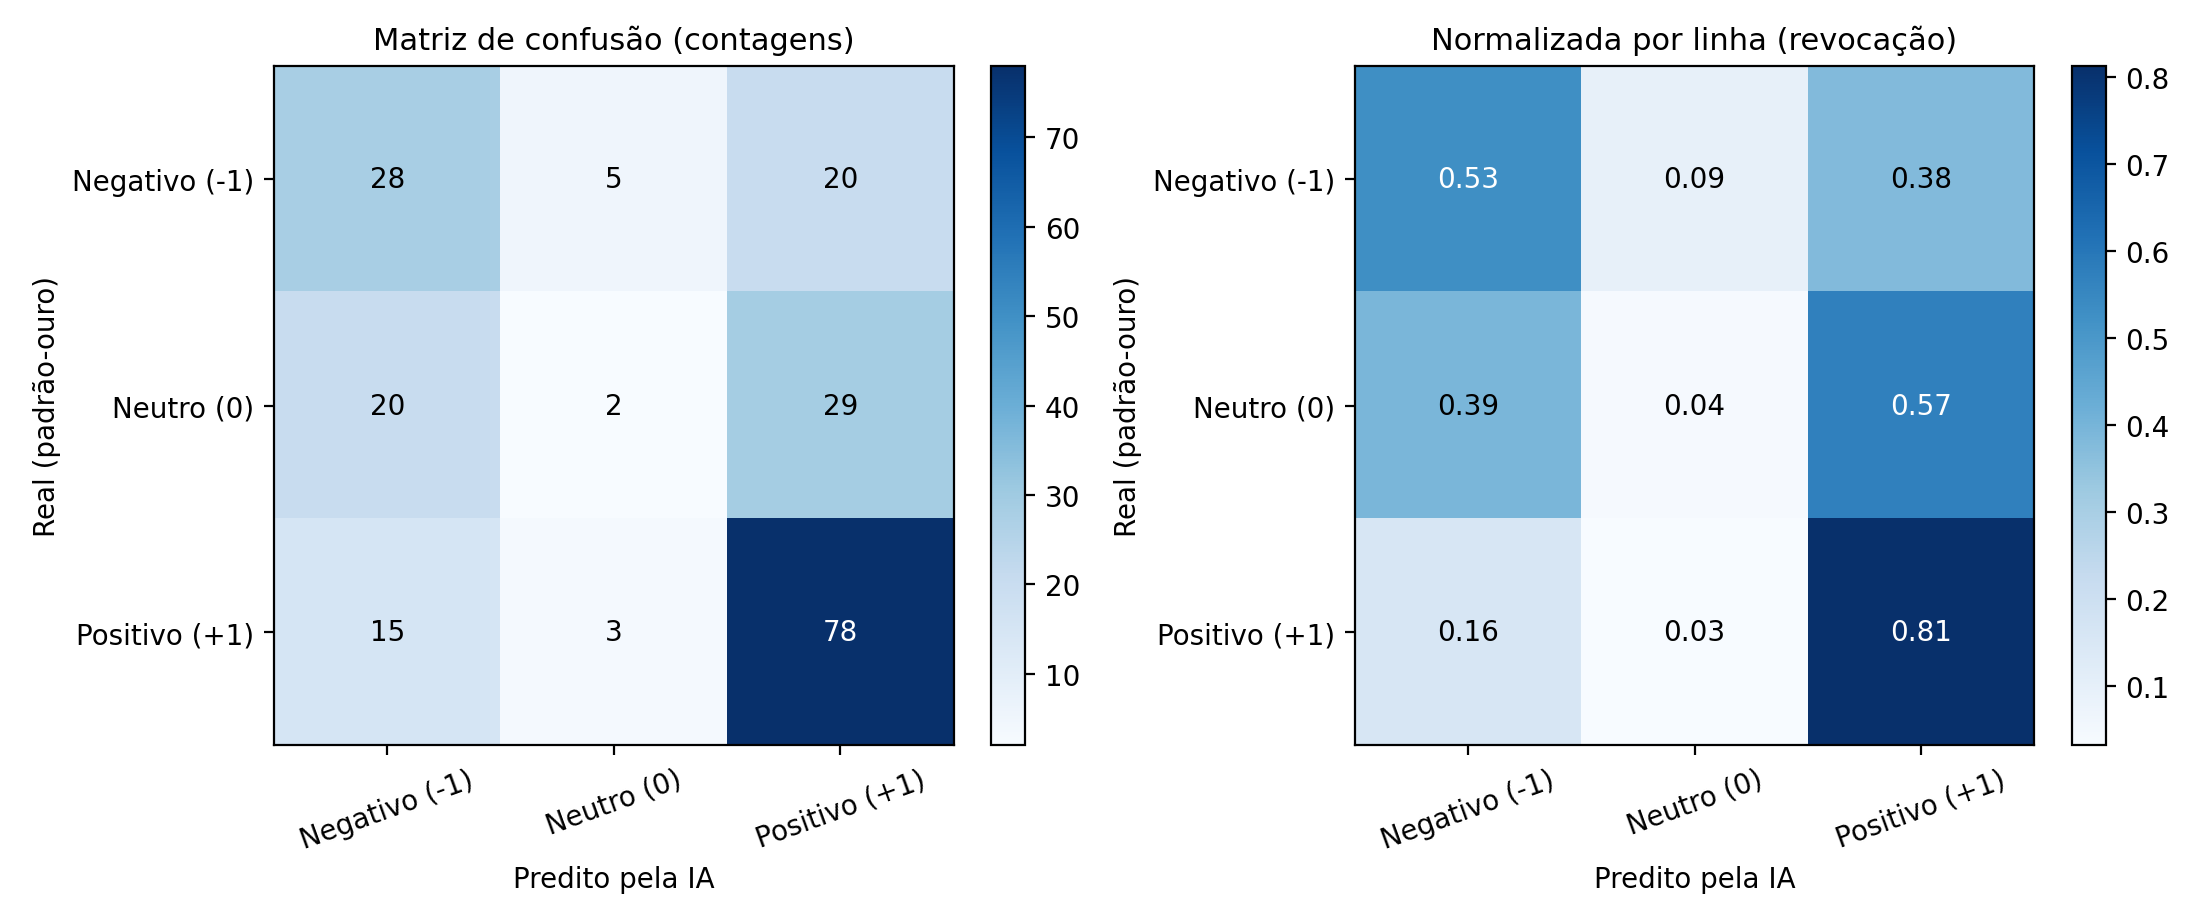

Figura salva em: /content/resultados_metricas/matriz_confusao.png


In [ ]:
saida = Path(PASTA_SAIDA); saida.mkdir(parents=True, exist_ok=True)
caminho_fig = saida / "matriz_confusao.png"
if salvar_figura(cm, ROTULOS, caminho_fig):
    from IPython.display import Image, display
    display(Image(filename=str(caminho_fig)))
    print("Figura salva em:", caminho_fig.resolve())

## 6. Curva ROC (um-contra-todos)

Sem `PROB_COLS`, a ROC usa a predição dura (0/1) e cada classe vira **um ponto** ligado a (0,0) e (1,1); o AUC então vale (revocação + especificidade)/2. Com probabilidades por classe, a curva é completa.

=== ROC-AUC (um-contra-todos) ===
Negativo (-1)  : AUC = 0.6451
Neutro (0)     : AUC = 0.4928
Positivo (+1)  : AUC = 0.6707
Média macro    : AUC = 0.6028

=== PONTOS DA CURVA (FPR, TPR) === [predições duras]
       Classe    FPR    TPR
Negativo (-1) 0.0000 0.0000
Negativo (-1) 0.2381 0.5283
Negativo (-1) 1.0000 1.0000
   Neutro (0) 0.0000 0.0000
   Neutro (0) 0.0537 0.0392
   Neutro (0) 1.0000 1.0000
Positivo (+1) 0.0000 0.0000
Positivo (+1) 0.4712 0.8125
Positivo (+1) 1.0000 1.0000


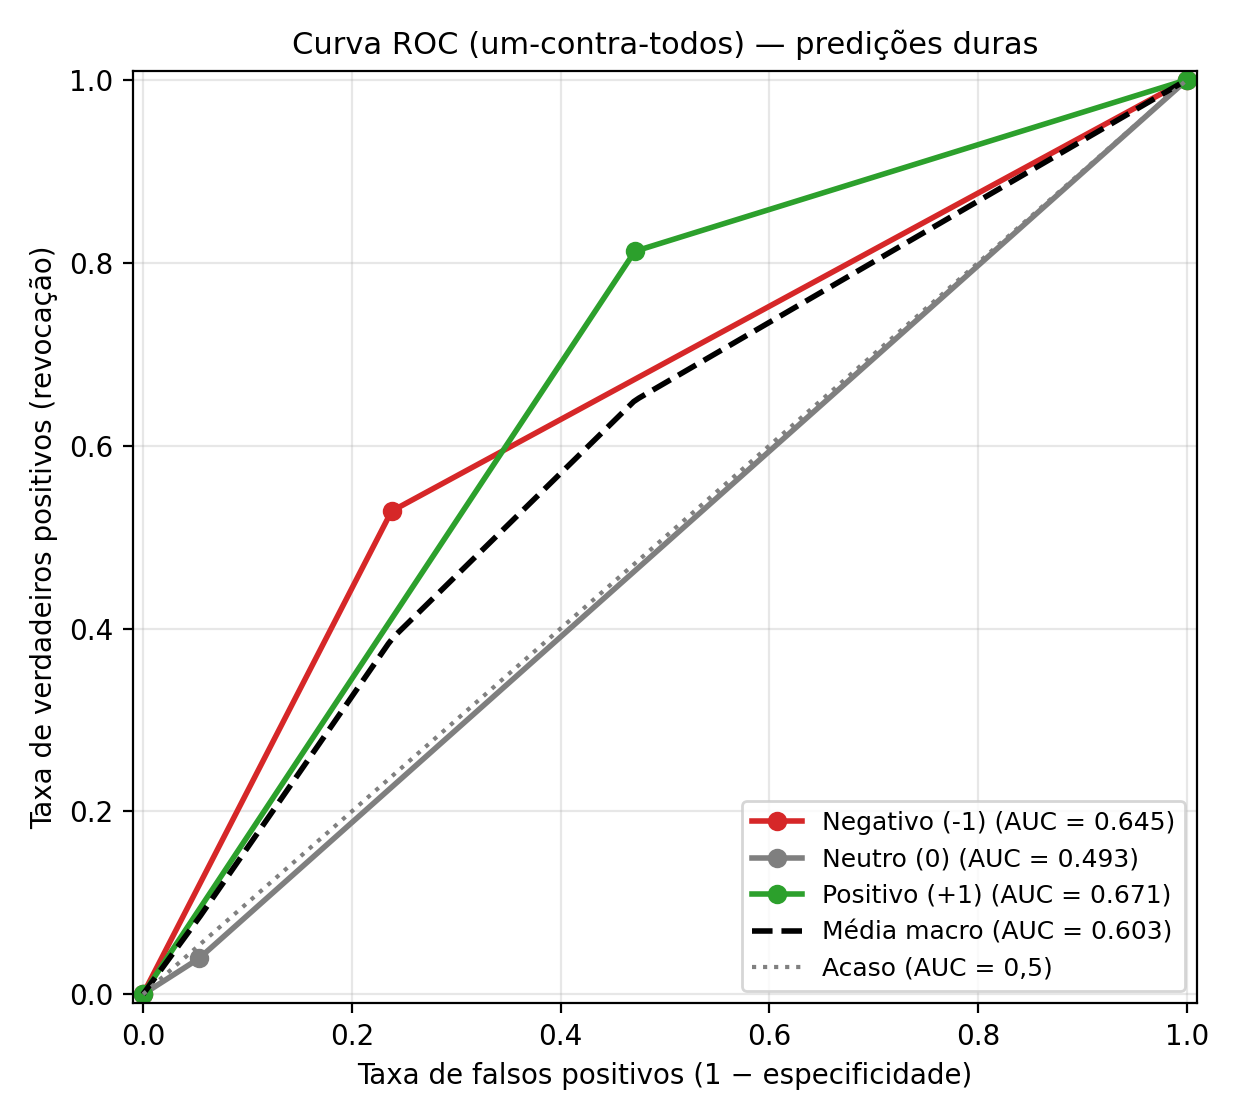

Figura salva em: /content/resultados_metricas/curva_roc.png


In [ ]:
curvas, macro = roc_ovr(y_gold, y_pred, ROTULOS, probas)
com_probas = probas is not None

print("=== ROC-AUC (um-contra-todos) ===")
for r in ROTULOS:
    print(f"{NOMES[r]:<15}: AUC = {curvas[r][2]:.4f}")
print(f"{'Média macro':<15}: AUC = {macro[2]:.4f}")

linhas = []
for r in ROTULOS:
    fpr, tpr, _ = curvas[r]
    linhas += [{"Classe": NOMES[r], "FPR": f, "TPR": t} for f, t in zip(fpr, tpr)]
roc_pontos = pd.DataFrame(linhas)
print("\n=== PONTOS DA CURVA (FPR, TPR) ===" + ("" if com_probas else " [predições duras]"))
print((roc_pontos if not com_probas else roc_pontos.groupby("Classe").head(5)).to_string(index=False))
if com_probas:
    print("(mostrando só os 5 primeiros pontos por classe; todos estão em roc_pontos.csv)")

caminho_roc = saida / "curva_roc.png"
if salvar_roc(curvas, macro, ROTULOS, caminho_roc, com_probas):
    from IPython.display import Image, display
    display(Image(filename=str(caminho_roc)))
    print("Figura salva em:", caminho_roc.resolve())

## 7. Salvar tabelas (e baixar tudo no Colab)

In [ ]:
cm_df.to_csv(saida / "matriz_confusao.csv", encoding="utf-8-sig")
roc_pontos.to_csv(saida / "roc_pontos.csv", index=False, encoding="utf-8-sig")
por_classe.to_csv(saida / "metricas_por_classe.csv", index=False, encoding="utf-8-sig")
pd.DataFrame({"Métrica": list(globais), "Valor": list(globais.values())}).to_csv(
    saida / "metricas_globais.csv", index=False, encoding="utf-8-sig")
print("Salvo em:", saida.resolve())

if EM_COLAB:
    import shutil
    files.download(shutil.make_archive(PASTA_SAIDA, "zip", PASTA_SAIDA))

Salvo em: /content/resultados_metricas


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>